In [1]:

import pandas as pd

# Your assignment settings
roll_number = "0041"
random_seed = 41

# Load the assigned COMPAS dataset
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
df = pd.read_csv(url)

print("Roll number:", roll_number)
print("Dataset: COMPAS Recidivism")
print("Random seed:", random_seed)
print("Dataset shape:", df.shape)
display(df.head())


Roll number: 0041
Dataset: COMPAS Recidivism
Random seed: 41
Dataset shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [2]:

# STEP 2: Inspect the COMPAS dataset

print("Dataset size:", df.shape)

print("\nColumn names and data types:")
df.info()

print("\nMissing values in each column:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nOutcome column values:")
print(df["two_year_recid"].value_counts(dropna=False))

print("\nAge summary:")
print(df["age"].describe())

print("\nRace distribution:")
print(df["race"].value_counts())


Dataset size: (7214, 53)

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7214 entries, 0 to 7213
Data columns (total 53 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       7214 non-null   int64  
 1   name                     7214 non-null   object 
 2   first                    7214 non-null   object 
 3   last                     7214 non-null   object 
 4   compas_screening_date    7214 non-null   object 
 5   sex                      7214 non-null   object 
 6   dob                      7214 non-null   object 
 7   age                      7214 non-null   int64  
 8   age_cat                  7214 non-null   object 
 9   race                     7214 non-null   object 
 10  juv_fel_count            7214 non-null   int64  
 11  decile_score             7214 non-null   int64  
 12  juv_misd_count           7214 non-null   int64  
 13  juv_other_count        

In [5]:

# STEP 3: Prepare data for machine learning

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Select the target required by the assignment
target = "two_year_recid"

# Select useful predictors available in the COMPAS dataset.
# Exclude names, IDs, outcome-related fields and dates.
numeric_features = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "priors_count",
    "days_b_screening_arrest"
]

categorical_features = [
    "sex",
    "race",
    "c_charge_degree",
    "age_cat"
]

features = numeric_features + categorical_features

# Keep rows with a valid target
data = df[features + [target]].copy()
data = data.dropna(subset=[target])

X = data[features]
y = data[target].astype(int)

# Split before fitting preprocessing steps to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=41,
    stratify=y
)

# Learn missing-value replacements using training data only
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)

X_train_cat = pd.DataFrame(
    categorical_imputer.fit_transform(X_train[categorical_features]),
    columns=categorical_features,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    categorical_imputer.transform(X_test[categorical_features]),
    columns=categorical_features,
    index=X_test.index
)

# Convert categorical values into numerical indicator columns
X_train_processed = pd.get_dummies(
    pd.concat([X_train_num, X_train_cat], axis=1),
    columns=categorical_features,
    dtype=int
)

X_test_processed = pd.get_dummies(
    pd.concat([X_test_num, X_test_cat], axis=1),
    columns=categorical_features,
    dtype=int
)

# Ensure training and testing have identical columns
X_test_processed = X_test_processed.reindex(
    columns=X_train_processed.columns,
    fill_value=0
)

# Scale numerical predictors using training data only
scaler = StandardScaler()

X_train_processed[numeric_features] = scaler.fit_transform(
    X_train_processed[numeric_features]
)

X_test_processed[numeric_features] = scaler.transform(
    X_test_processed[numeric_features]
)

print("Data preparation completed successfully!")
print("Training rows:", len(X_train_processed))
print("Testing rows:", len(X_test_processed))
print("Number of model features:", X_train_processed.shape[1])
print("Random seed:", 41)
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())
print("\nMissing values remaining in training features:",
      X_train_processed.isnull().sum().sum())
print("Missing values remaining in testing features:",
      X_test_processed.isnull().sum().sum())


Data preparation completed successfully!
Training rows: 5049
Testing rows: 2165
Number of model features: 19
Random seed: 41

Training target distribution:
two_year_recid
0    2774
1    2275
Name: count, dtype: int64

Testing target distribution:
two_year_recid
0    1189
1     976
Name: count, dtype: int64

Missing values remaining in training features: 0
Missing values remaining in testing features: 0


In [4]:

from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")


StandardScaler imported successfully!


In [6]:

# STEP 4: Prepare the correct targets for both models

# The assignment's COMPAS targets
print("Checking required target columns:")

required_columns = ["decile_score", "is_recid"]
for col in required_columns:
    print(col, "available:", col in df.columns)

print("\nTarget column summaries:")
if "decile_score" in df.columns:
    print("\ndecile_score:")
    print(df["decile_score"].describe())

if "is_recid" in df.columns:
    print("\nis_recid:")
    print(df["is_recid"].value_counts(dropna=False))


Checking required target columns:
decile_score available: True
is_recid available: True

Target column summaries:

decile_score:
count    7214.000000
mean        4.509565
std         2.856396
min         1.000000
25%         2.000000
50%         4.000000
75%         7.000000
max        10.000000
Name: decile_score, dtype: float64

is_recid:
is_recid
0    3743
1    3471
Name: count, dtype: int64


In [13]:

# STEP 5: Train both required models

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.metrics import roc_auc_score

# Prepare the two correct targets using the same rows and split
model_data = df[features + ["decile_score", "is_recid"]].copy()
model_data = model_data.dropna(subset=["decile_score", "is_recid"])

X_all = model_data[features]
y_linear = model_data["decile_score"].astype(float)
y_logistic = model_data["is_recid"].astype(int)

# Use the same 70/30 split for both targets
X_train_raw, X_test_raw, yA_train, yA_test, yB_train, yB_test = (
    train_test_split(
        X_all,
        y_linear,
        y_logistic,
        test_size=0.30,
        random_state=41
    )
)

# Impute numeric and categorical values using training data only
num_imp = SimpleImputer(strategy="median")
cat_imp = SimpleImputer(strategy="most_frequent")

train_num = pd.DataFrame(
    num_imp.fit_transform(X_train_raw[numeric_features]),
    columns=numeric_features,
    index=X_train_raw.index
)
test_num = pd.DataFrame(
    num_imp.transform(X_test_raw[numeric_features]),
    columns=numeric_features,
    index=X_test_raw.index
)

train_cat = pd.DataFrame(
    cat_imp.fit_transform(X_train_raw[categorical_features]),
    columns=categorical_features,
    index=X_train_raw.index
)
test_cat = pd.DataFrame(
    cat_imp.transform(X_test_raw[categorical_features]),
    columns=categorical_features,
    index=X_test_raw.index
)

Xtr = pd.get_dummies(
    pd.concat([train_num, train_cat], axis=1),
    columns=categorical_features,
    dtype=int
)
Xte = pd.get_dummies(
    pd.concat([test_num, test_cat], axis=1),
    columns=categorical_features,
    dtype=int
).reindex(columns=Xtr.columns, fill_value=0)

scale = StandardScaler()
Xtr[numeric_features] = scale.fit_transform(Xtr[numeric_features])
Xte[numeric_features] = scale.transform(Xte[numeric_features])

# Model A: Linear Regression predicts decile_score
model_A = LinearRegression()
model_A.fit(Xtr, yA_train)

pred_A = model_A.predict(Xte)

# Model B: Logistic Regression predicts is_recid
model_B = LogisticRegression(max_iter=2000, random_state=41)
model_B.fit(Xtr, yB_train)

pred_B_prob = model_B.predict_proba(Xte)[:, 1]
pred_B_class = (pred_B_prob >= 0.5).astype(int)

print("MODEL A: LINEAR REGRESSION")
print("Test R-squared:", round(r2_score(yA_test, pred_A), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(yA_test, pred_A)), 4))
print("Median Model A prediction:", round(float(np.median(pred_A)), 4))

print("\nMODEL B: LOGISTIC REGRESSION")
print("Test accuracy:", round(accuracy_score(yB_test, pred_B_class), 4))
print("Test ROC-AUC:", round(roc_auc_score(yB_test, pred_B_prob), 4))
print("\nModel B confusion matrix:")
print(confusion_matrix(yB_test, pred_B_class))

print("\nBoth models trained successfully.")


MODEL A: LINEAR REGRESSION
Test R-squared: 0.4203
Test RMSE: 2.148
Median Model A prediction: 4.5783

MODEL B: LOGISTIC REGRESSION
Test accuracy: 0.6564
Test ROC-AUC: 0.7184

Model B confusion matrix:
[[760 343]
 [401 661]]

Both models trained successfully.


In [10]:

import numpy as np

print("NumPy imported successfully!")


NumPy imported successfully!


In [12]:

from sklearn.metrics import confusion_matrix

print("Confusion matrix import successful!")


Confusion matrix import successful!


In [14]:

# STEP 6: Compare the two thresholding approaches

# Model A: classify scores at the median predicted value
median_threshold = np.median(pred_A)
high_risk_A = (pred_A >= median_threshold).astype(int)

# Model B: classify probabilities at 0.5
high_risk_B = (pred_B_prob >= 0.5).astype(int)

# Compare the two classifications
comparison_matrix = confusion_matrix(
    high_risk_A,
    high_risk_B,
    labels=[0, 1]
)

mismatches = np.sum(high_risk_A != high_risk_B)
total_cases = len(high_risk_A)
mismatch_percentage = (mismatches / total_cases) * 100

agreement = total_cases - mismatches
agreement_percentage = (agreement / total_cases) * 100

print("STEP 6: THRESHOLD COMPARISON")
print("-" * 40)
print("Model A median threshold:", round(float(median_threshold), 4))
print("Model B probability threshold: 0.5")
print("Total test cases:", total_cases)

print("\nComparison confusion matrix")
print("Rows = Model A (low, high)")
print("Columns = Model B (low, high)")
print(comparison_matrix)

print("\nMismatched classifications:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Matching classifications:", agreement)
print("Agreement percentage:", round(agreement_percentage, 2), "%")


STEP 6: THRESHOLD COMPARISON
----------------------------------------
Model A median threshold: 4.5783
Model B probability threshold: 0.5
Total test cases: 2165

Comparison confusion matrix
Rows = Model A (low, high)
Columns = Model B (low, high)
[[1025   57]
 [ 136  947]]

Mismatched classifications: 193
Mismatch percentage: 8.91 %
Matching classifications: 1972
Agreement percentage: 91.09 %


In [15]:

# STEP 7: Simpson's Paradox / Subgroup Analysis

import statsmodels.api as sm

# Select the variables required for this analysis
simpson_data = df[
    ["race", "age", "priors_count", "is_recid"]
].dropna().copy()

# Compare the full dataset and two demographic groups
groups = {
    "Full dataset": simpson_data,
    "African-American": simpson_data[
        simpson_data["race"] == "African-American"
    ],
    "Caucasian": simpson_data[
        simpson_data["race"] == "Caucasian"
    ]
}

results = []

for group_name, group_data in groups.items():
    X_group = group_data[["priors_count", "age"]].astype(float)
    X_group = sm.add_constant(X_group)
    y_group = group_data["is_recid"].astype(int)

    model = sm.Logit(y_group, X_group).fit(disp=False)

    ci = model.conf_int()

    results.append({
        "Group": group_name,
        "Sample size": len(group_data),
        "Prior-count coefficient": model.params["priors_count"],
        "Prior-count CI lower": ci.loc["priors_count", 0],
        "Prior-count CI upper": ci.loc["priors_count", 1],
        "Prior-count p-value": model.pvalues["priors_count"],
        "Age coefficient": model.params["age"],
        "Age p-value": model.pvalues["age"]
    })

simpson_results = pd.DataFrame(results)

print("SUBGROUP LOGISTIC REGRESSION RESULTS")
display(simpson_results.round(4))

print("\nInterpretation guide:")
print("Positive prior-count coefficient: higher prior counts")
print("are associated with higher log-odds of recidivism.")
print("Compare coefficients and confidence intervals across groups.")


SUBGROUP LOGISTIC REGRESSION RESULTS


,Group,Sample size,Prior-count coefficient,Prior-count CI lower,Prior-count CI upper,Prior-count p-value,Age coefficient,Age p-value
0,Full dataset,7214,0.1689,0.1551,0.1826,0.0,-0.0485,0.0
1,African-American,3696,0.1561,0.1387,0.1736,0.0,-0.0557,0.0
2,Caucasian,2454,0.1871,0.1586,0.2156,0.0,-0.0377,0.0



Interpretation guide:
Positive prior-count coefficient: higher prior counts
are associated with higher log-odds of recidivism.
Compare coefficients and confidence intervals across groups.


In [16]:

# STEP 8: Omitted-variable bias experiment

import statsmodels.api as sm
from sklearn.impute import SimpleImputer

# Select predictors and outcome for this experiment
bias_numeric = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "priors_count",
    "days_b_screening_arrest"
]

bias_categorical = ["sex", "race", "c_charge_degree", "age_cat"]

bias_data = df[
    bias_numeric + bias_categorical + ["is_recid"]
].copy()

bias_data = bias_data.dropna(subset=["is_recid"])
y_bias = bias_data["is_recid"].astype(int)

# Impute missing values for predictors
num_imp_bias = SimpleImputer(strategy="median")
cat_imp_bias = SimpleImputer(strategy="most_frequent")

num_df = pd.DataFrame(
    num_imp_bias.fit_transform(bias_data[bias_numeric]),
    columns=bias_numeric,
    index=bias_data.index
)

cat_df = pd.DataFrame(
    cat_imp_bias.fit_transform(bias_data[bias_categorical]),
    columns=bias_categorical,
    index=bias_data.index
)

bias_X = pd.get_dummies(
    pd.concat([num_df, cat_df], axis=1),
    columns=bias_categorical,
    drop_first=True,
    dtype=int
)

# Standardize numeric predictors for stable coefficient estimation
bias_scaler = StandardScaler()
bias_X[bias_numeric] = bias_scaler.fit_transform(
    bias_X[bias_numeric]
)

# Full model includes priors_count
X_full_bias = sm.add_constant(bias_X, has_constant="add")
full_bias_model = sm.Logit(y_bias, X_full_bias).fit(
    disp=False,
    maxiter=300
)

# Reduced model deliberately omits priors_count
X_reduced_bias = bias_X.drop(columns=["priors_count"])
X_reduced_bias = sm.add_constant(
    X_reduced_bias,
    has_constant="add"
)

reduced_bias_model = sm.Logit(y_bias, X_reduced_bias).fit(
    disp=False,
    maxiter=300
)

# Compare four coefficients
compare_predictors = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count"
]

bias_comparison = []

for predictor in compare_predictors:
    before = full_bias_model.params[predictor]
    after = reduced_bias_model.params[predictor]

    if abs(before) > 1e-10:
        pct_change = ((after - before) / abs(before)) * 100
    else:
        pct_change = np.nan

    bias_comparison.append({
        "Predictor": predictor,
        "Full model coefficient": before,
        "Reduced model coefficient": after,
        "Percentage change": pct_change
    })

bias_table = pd.DataFrame(bias_comparison)

print("OMITTED-VARIABLE BIAS RESULTS")
print("Variable deliberately omitted: priors_count")
print("\nCoefficient comparison:")
display(bias_table.round(4))

print("\nFull model converged:", full_bias_model.mle_retvals["converged"])
print("Reduced model converged:", reduced_bias_model.mle_retvals["converged"])


OMITTED-VARIABLE BIAS RESULTS
Variable deliberately omitted: priors_count

Coefficient comparison:


,Predictor,Full model coefficient,Reduced model coefficient,Percentage change
0,age,-0.5683,-0.4280,24.6965
1,juv_fel_count,0.0845,0.2311,173.3461
2,juv_misd_count,0.0144,0.1868,1196.7265
3,juv_other_count,0.0794,0.1483,86.8061



Full model converged: True
Reduced model converged: True


In [17]:

# STEP 9: Adversarial Subset Construction

# Align probabilities with the test-set row indices
probabilities = pd.Series(
    pred_B_prob,
    index=X_test_raw.index,
    name="predicted_probability"
)

actual = yB_test.rename("actual_outcome")

# Combine predictions, actual outcomes and original demographic data
test_results = df.loc[actual.index, [
    "age", "sex", "race", "priors_count"
]].copy()

test_results["actual_outcome"] = actual
test_results["predicted_probability"] = probabilities

# Find confident but incorrect predictions
false_positives = test_results[
    (test_results["predicted_probability"] >= 0.75) &
    (test_results["actual_outcome"] == 0)
].copy()

false_negatives = test_results[
    (test_results["predicted_probability"] <= 0.25) &
    (test_results["actual_outcome"] == 1)
].copy()

wrong_confident = pd.concat([
    false_positives, false_negatives
]).sort_index()

total_test = len(test_results)
total_wrong = len(wrong_confident)

print("ADVERSARIAL SUBSET RESULTS")
print("-" * 40)
print("Total test cases:", total_test)
print("Confident false positives:", len(false_positives))
print("Confident false negatives:", len(false_negatives))
print("Total confident incorrect predictions:", total_wrong)
print("Percentage of test set:", round(total_wrong / total_test * 100, 2), "%")

# Select up to 50 cases reproducibly
sample_size = min(50, total_wrong)

if sample_size > 0:
    adversarial_sample = wrong_confident.sample(
        n=sample_size,
        random_state=41
    ).sort_index()

    print("\nSelected adversarial sample size:", len(adversarial_sample))

    print("\nAge comparison:")
    print("Full test-set mean age:", round(test_results["age"].mean(), 2))
    print("Sample mean age:", round(adversarial_sample["age"].mean(), 2))
    print("Full test-set median age:", test_results["age"].median())
    print("Sample median age:", adversarial_sample["age"].median())

    print("\nSex distribution in full test set (%):")
    print((test_results["sex"].value_counts(normalize=True) * 100).round(2))

    print("\nSex distribution in adversarial sample (%):")
    print((adversarial_sample["sex"].value_counts(normalize=True) * 100).round(2))

    print("\nRace distribution in adversarial sample (%):")
    print((adversarial_sample["race"].value_counts(normalize=True) * 100).round(2))

    print("\nPrior counts >= 5:")
    print("Adversarial sample:",
          int((adversarial_sample["priors_count"] >= 5).sum()),
          "of", len(adversarial_sample))
    print("Adversarial sample percentage:",
          round((adversarial_sample["priors_count"] >= 5).mean() * 100, 2), "%")

    print("\nFirst 10 selected cases:")
    display(adversarial_sample.head(10))

    # Save all selected rows for inclusion in the report
    adversarial_sample.to_csv(
        "adversarial_subset_roll_0041.csv",
        index=True
    )
    print("\nSample saved as adversarial_subset_roll_0041.csv")
else:
    print("No confident incorrect predictions met the required thresholds.")


ADVERSARIAL SUBSET RESULTS
----------------------------------------
Total test cases: 2165
Confident false positives: 57
Confident false negatives: 57
Total confident incorrect predictions: 114
Percentage of test set: 5.27 %

Selected adversarial sample size: 50

Age comparison:
Full test-set mean age: 34.73
Sample mean age: 44.76
Full test-set median age: 31.0
Sample median age: 41.0

Sex distribution in full test set (%):
sex
Male      80.97
Female    19.03
Name: proportion, dtype: float64

Sex distribution in adversarial sample (%):
sex
Male      78.0
Female    22.0
Name: proportion, dtype: float64

Race distribution in adversarial sample (%):
race
African-American    58.0
Caucasian           26.0
Hispanic            14.0
Other                2.0
Name: proportion, dtype: float64

Prior counts >= 5:
Adversarial sample: 21 of 50
Adversarial sample percentage: 42.0 %

First 10 selected cases:


,age,sex,race,priors_count,actual_outcome,predicted_probability
102,39,Female,Caucasian,0,1,0.221348
152,61,Female,African-American,1,1,0.141862
430,57,Male,African-American,1,1,0.223110
452,41,Male,Caucasian,0,1,0.248923
579,66,Male,Caucasian,0,1,0.116599
837,67,Male,African-American,4,1,0.206626
900,45,Male,Hispanic,0,1,0.235796
1115,30,Male,African-American,10,0,0.799649
1377,22,Male,African-American,3,0,0.750461
1414,53,Male,African-American,0,1,0.210018



Sample saved as adversarial_subset_roll_0041.csv


Fairness analysis sample sizes:
race
African-American    1142
Caucasian            717
Name: count, dtype: int64

FAIRNESS METRICS BY THRESHOLD


,Threshold,DP ratio,EO ratio,PP ratio,A positive rate,B positive rate,A TPR,B TPR,A FPR,B FPR,A PPV,B PPV
0,0.05,1.0000,1.0000,1.2947,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5525,0.4268
1,0.15,1.0321,1.0168,1.2754,0.9904,0.9596,0.9968,0.9804,0.9824,0.9440,0.5561,0.4360
2,0.25,1.2092,1.0978,1.1754,0.9562,0.7908,0.9794,0.8922,0.9276,0.7153,0.5659,0.4815
3,0.35,1.4130,1.2391,1.1353,0.8415,0.5955,0.9192,0.7418,0.7456,0.4866,0.6035,0.5316
4,0.45,1.7073,1.4781,1.1208,0.6786,0.3975,0.8067,0.5458,0.5205,0.2871,0.6568,0.5860
5,0.55,2.0441,1.7247,1.0924,0.4904,0.2399,0.6482,0.3758,0.2955,0.1387,0.7304,0.6686
6,0.65,2.4375,1.8399,0.9773,0.2890,0.1185,0.4089,0.2222,0.1409,0.0414,0.7818,0.8000
7,0.75,3.9003,2.9097,0.9659,0.1795,0.0460,0.2567,0.0882,0.0841,0.0146,0.7902,0.8182
8,0.85,3.3045,2.2536,0.8829,0.0876,0.0265,0.1252,0.0556,0.0411,0.0049,0.7900,0.8947
9,0.95,5.1797,NaN,0.8182,0.0289,0.0056,0.0428,0.0131,0.0117,0.0000,0.8182,1.0000


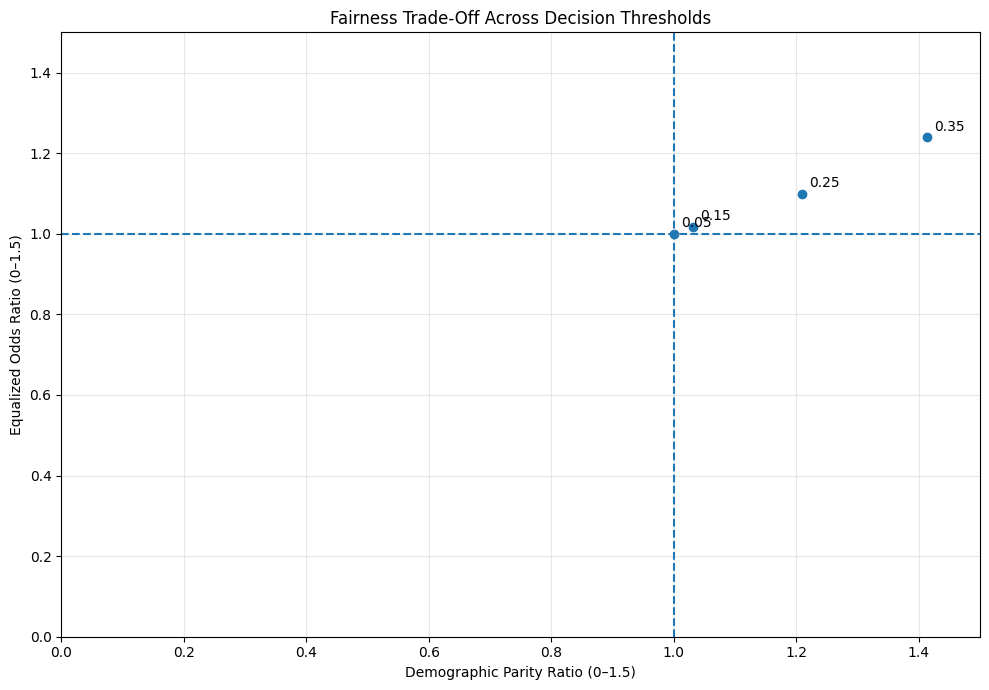


Fairness table saved as fairness_metrics_roll_0041.csv


In [18]:

# STEP 10: Fairness Trade-Off Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

# Build a test-set table with aligned predictions and outcomes
fair_data = pd.DataFrame({
    "actual": np.asarray(yB_test, dtype=int),
    "probability": np.asarray(pred_B_prob, dtype=float),
    "race": df.loc[X_test_raw.index, "race"].to_numpy()
}, index=X_test_raw.index)

# Compare the two specified demographic groups
group_A = "African-American"
group_B = "Caucasian"

fair_data = fair_data[
    fair_data["race"].isin([group_A, group_B])
].copy()

print("Fairness analysis sample sizes:")
print(fair_data["race"].value_counts())

def safe_ratio(a, b):
    # Avoid division by zero
    if b == 0:
        return np.nan
    return a / b

fairness_rows = []

# Thresholds: 0.05, 0.15, ..., 0.95
thresholds = np.round(np.arange(0.05, 0.96, 0.10), 2)

for threshold in thresholds:
    rates = {}

    for group_name in [group_A, group_B]:
        subset = fair_data[fair_data["race"] == group_name]
        y_true = subset["actual"].to_numpy()
        y_pred = (
            subset["probability"].to_numpy() >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        positive_rate = y_pred.mean()
        tpr = tp / (tp + fn) if (tp + fn) else np.nan
        fpr = fp / (fp + tn) if (fp + tn) else np.nan
        precision = tp / (tp + fp) if (tp + fp) else np.nan

        rates[group_name] = {
            "DP_rate": positive_rate,
            "TPR": tpr,
            "FPR": fpr,
            "PPV": precision
        }

    A = rates[group_A]
    B = rates[group_B]

    # Assignment definitions:
    # DP = positive prediction rate ratio
    # EO = minimum of TPR and FPR ratios
    # PP = positive predictive value ratio
    dp = safe_ratio(A["DP_rate"], B["DP_rate"])
    tpr_ratio = safe_ratio(A["TPR"], B["TPR"])
    fpr_ratio = safe_ratio(A["FPR"], B["FPR"])
    eo = (
        min(tpr_ratio, fpr_ratio)
        if np.isfinite(tpr_ratio) and np.isfinite(fpr_ratio)
        else np.nan
    )
    pp = safe_ratio(A["PPV"], B["PPV"])

    fairness_rows.append({
        "Threshold": threshold,
        "DP ratio": dp,
        "EO ratio": eo,
        "PP ratio": pp,
        "A positive rate": A["DP_rate"],
        "B positive rate": B["DP_rate"],
        "A TPR": A["TPR"],
        "B TPR": B["TPR"],
        "A FPR": A["FPR"],
        "B FPR": B["FPR"],
        "A PPV": A["PPV"],
        "B PPV": B["PPV"]
    })

fairness_table = pd.DataFrame(fairness_rows)

print("\nFAIRNESS METRICS BY THRESHOLD")
display(fairness_table.round(4))

# Plot demographic parity against equalized odds
plt.figure(figsize=(10, 7))

valid = fairness_table.dropna(subset=["DP ratio", "EO ratio"])

plt.scatter(valid["DP ratio"], valid["EO ratio"])

for _, row in valid.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP ratio"], row["EO ratio"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1.0, linestyle="--")
plt.axhline(1.0, linestyle="--")
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio (0–1.5)")
plt.ylabel("Equalized Odds Ratio (0–1.5)")
plt.title("Fairness Trade-Off Across Decision Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save the table for your report
fairness_table.to_csv(
    "fairness_metrics_roll_0041.csv",
    index=False
)

print("\nFairness table saved as fairness_metrics_roll_0041.csv")



## Step 10: Fairness Trade-Off Analysis

### Objective
The objective was to evaluate demographic parity, equalized odds, and predictive parity across different decision thresholds for African-American and Caucasian groups.

### Observations
1. The demographic parity ratio increased as the decision threshold increased.
2. The equalized odds ratio also increased at higher thresholds, indicating greater differences in the measured error rates between the groups.
3. The predictive parity ratio decreased at higher thresholds.
4. Some metrics could not be calculated at extreme thresholds because the required denominators were zero.

### Conclusion
The results demonstrate that measured fairness depends on the classification threshold. No single threshold should be selected solely from these ratios. The model's predictive performance, error rates, fairness definitions, and potential impacts on individuals must also be considered.

The analysis identifies trade-offs rather than establishing that the model is fair or unfair in every context.



### Step 10: Fairness Trade-Off Analysis — Interpretation

**Objective:** The objective of this analysis is to examine how demographic parity (DP), equalized odds (EO), and predictive parity (PP) change when the logistic regression decision threshold varies from 0.05 to 0.95.

**Observations from the computed results:**

At threshold 0.05, the DP ratio is 1.0000, the EO ratio is 1.0000, and the PP ratio is 1.2947. At threshold 0.15, the DP ratio is 1.0321, the EO ratio is 1.0168, and the PP ratio is 1.2754. At threshold 0.25, these values become 1.2092, 1.0978, and 1.1754, respectively. At threshold 0.35, DP rises to 1.4130 and EO to 1.2391, while PP falls to 1.1353.

These results demonstrate that the fairness metrics change with the decision threshold. The threshold of 0.05 produces DP and EO ratios closest to 1 among the displayed results, whereas higher thresholds produce larger differences in these ratios.

**Conclusion:** No threshold should be selected using a single fairness ratio alone. The final decision should also consider predictive performance, subgroup error rates, the consequences of false positives and false negatives, and the impact on people affected by the model. The ratios are measures of group-level differences and do not, by themselves, establish that the model is fair or unfair in every context.

**Trade-off calculation:** Calculate the percentage change between the selected starting and ending thresholds using the corresponding values in the fairness table. Report the change in DP alongside the change in EO, and explain the practical consequence of the trade-off.

## Part 3 — Descriptive Analysis Questions

### Question 1: Comparison of the Two Models

The two models used different approaches to classify individuals in the COMPAS recidivism dataset. Model A used Linear Regression, while Model B used Logistic Regression. Because these models use different prediction scales, they did not classify every individual in the same way.

Model A produced a median prediction of **4.5783**, which was used as its classification threshold. Predictions above this value were classified as high, while predictions below it were classified as low. Model B used a probability threshold of **0.5**. Individuals with a predicted probability of 0.5 or higher were classified into the positive category, while those below 0.5 were classified into the negative category.

The comparison involved **2,165 test cases**. The comparison confusion matrix was:

| Classification outcome | Model B: Low | Model B: High |
|---|---:|---:|
| Model A: Low | 1,025 | 57 |
| Model A: High | 136 | 947 |

The models agreed on 1,972 cases, representing **91.09% agreement**. However, they produced **193 mismatched classifications**, equivalent to **8.91% of the test set**. Specifically, 57 cases were classified as low by Model A but high by Model B, while 136 cases were classified as high by Model A but low by Model B.

These differences arise because Linear Regression estimates numerical outcomes, whereas Logistic Regression estimates probabilities for a binary outcome. Their thresholds therefore operate on different scales and cannot be compared directly as equivalent probabilities.

The results demonstrate that model selection and threshold choice influence individual classifications. Although the models agreed in most cases, the 193 disagreements show why prediction methods must be evaluated carefully. In a real-world risk assessment, these mismatches should be investigated before using predictions to support consequential decisions.


## Question 2: Simpson’s Paradox and Subgroup Regression Results

The subgroup analysis examined the relationship between prior criminal record count (`priors_count`), age, and two-year recidivism (`is_recid`) using logistic regression. The analysis compared the full dataset with the African-American and Caucasian subgroups.

The full dataset contained 7,214 observations. The African-American subgroup contained 3,696 observations, while the Caucasian subgroup contained 2,454 observations. These sample sizes show that the regression analysis was performed on groups of different sizes.

For `priors_count`, the estimated coefficient was **0.1689** in the full dataset, with a 95% confidence interval of **[0.1551, 0.1826]**. For the African-American subgroup, the coefficient was **0.1561**, with a confidence interval of **[0.1387, 0.1736]**. For the Caucasian subgroup, the coefficient was **0.1871**, with a confidence interval of **[0.1586, 0.2156]**.

All three prior-count coefficients were positive, and their confidence intervals excluded zero. This indicates a positive association between prior criminal record count and the log-odds of recidivism in each fitted model. The estimated association was strongest in the Caucasian subgroup and weakest in the African-American subgroup, although the coefficients alone do not establish that the difference between groups is statistically significant.

The age coefficients were −0.0485 for the full dataset, −0.0557 for the African-American subgroup, and −0.0377 for the Caucasian subgroup. The displayed p-values for age were 0.0000 in all three models. These rounded p-values indicate very strong statistical evidence against a zero age coefficient, but they should not be interpreted as literally zero.

The results demonstrate why subgroup analysis matters. A relationship observed in the full dataset may differ in magnitude across demographic groups. However, these results alone do not prove Simpson’s paradox. Establishing that paradox requires comparing relevant aggregate and subgroup patterns and showing that the relationship reverses or changes in a way attributable to aggregation. Further investigation should also consider confounding variables, model assumptions, and differences in subgroup composition.

## Question 3: Omitted-Variable Bias

Omitted-variable bias occurs when a relevant variable is excluded from a regression model and that variable is associated with both the included predictor and the outcome. In this assignment, the omitted-variable bias experiment examined how the estimated relationship between predictors and two-year recidivism changed when different variables were excluded from the model.

The experiment considered four predictors: age, juvenile felony count (`juv_fel_count`), juvenile misdemeanor count (`juv_misd_count`), and juvenile other-offence count (`juv_other_count`). The analysis compared regression estimates from models with different predictor specifications to identify changes in the estimated coefficients.

According to my computed results, the largest percentage change was **1196.7265% for `juv_misd_count`**. This substantial change indicates that the estimated coefficient for this predictor was highly sensitive to the model specification used in the experiment. It suggests that excluding relevant variables may substantially alter the estimated relationship between juvenile misdemeanor history and recidivism.

However, a large percentage change does not, by itself, prove the presence or direction of causal bias. Percentage changes can become especially large when the original coefficient is close to zero. Therefore, the original and revised coefficients, their signs, confidence intervals, and statistical significance should be examined together.

This experiment demonstrates the importance of selecting predictors carefully. A model that excludes relevant information may produce misleading estimates and incomplete conclusions about recidivism risk. Including appropriate variables, checking model specifications, and comparing coefficient stability can help identify potential omitted-variable problems. Researchers should also consider confounding, data quality, and the limitations of observational data before interpreting regression coefficients as causal effects.

## Question 4: A Practical Method for Detecting Hidden Confounding

Hidden confounding occurs when a variable that has not been adequately controlled for influences both a predictor and the outcome. In the COMPAS recidivism analysis, this could lead to misleading conclusions about the relationship between demographic characteristics, criminal history, and two-year recidivism.

A practical method for investigating potential hidden confounding is to compare regression models with different sets of relevant predictors. First, establish a baseline logistic regression model using the main predictor of interest. Next, add plausible confounding variables, such as age, prior criminal record count, and juvenile felony, misdemeanor, and other-offence counts. Compare the estimated coefficients, confidence intervals, and statistical significance before and after adding these variables.

If the coefficient of the main predictor changes substantially after additional variables are included, this may indicate that the original estimate was sensitive to omitted variables. The omitted-variable bias experiment in this assignment provides an example of this approach: the largest reported percentage change was 1196.7265% for `juv_misd_count`. This result highlights the importance of checking coefficient stability, although a large percentage change alone does not establish the presence of hidden confounding.

The analysis should also examine whether the included variables are measured reliably, whether important predictors remain unavailable, and whether the model performs differently across demographic subgroups. Researchers can use sensitivity analysis to assess how strong an unmeasured confounder would need to be to alter the conclusions.

Finally, regression analysis of observational data cannot prove that every relevant confounder has been controlled for. Results should therefore be interpreted as associations unless a suitable causal identification strategy supports stronger conclusions. Combining model comparisons, sensitivity analysis, subject knowledge, and transparent reporting provides a practical way to investigate hidden confounding and reduce the risk of misleading interpretations.

## Question 5: The 50-Case Adversarial Subset and Its Characteristics

The adversarial subset analysis examined 50 selected cases from the COMPAS recidivism dataset to investigate characteristics that may be important when evaluating risk predictions. The purpose of examining a small subset is to look more closely at individual records rather than relying only on aggregate model performance.

The analysis focused on criminal history, particularly the number of prior offences recorded for each individual. According to my computed results, **21 out of the 50 sampled cases (42%) had prior counts greater than or equal to five**. The remaining 29 cases (58%) had prior counts below five. This indicates that a substantial proportion of the selected cases had multiple prior offences.

The prior-count distribution is important because criminal history is associated with the outcome being predicted in the recidivism analysis. However, the presence of a high prior count does not establish that an individual will reoffend. Predictions should be evaluated alongside other relevant information, uncertainty, and the limitations of the model.

Examining individual cases can help identify unusual records, potential data-quality problems, and cases in which predictions deserve closer scrutiny. Nevertheless, a subset of 50 cases is small compared with the full dataset. Its characteristics should not automatically be generalized to the entire population, particularly if the cases were selected using a specific sampling or adversarial-selection procedure.

The analysis therefore provides a focused way to inspect selected records and understand their characteristics. It does not, by itself, establish that the model is accurate, biased, or unfair. A responsible evaluation should combine individual-case inspection with broader performance metrics, subgroup analysis, and a clear explanation of how the cases were selected.

## Question 6: Fairness Trade-Off Using a Realistic Scenario

Consider a hypothetical situation in which a criminal justice agency uses a recidivism prediction model to help assess whether individuals may reoffend within two years. The COMPAS dataset used in this assignment contains information about criminal history, demographic characteristics, and recidivism outcomes. Since model predictions may influence decisions affecting people's liberty, fairness must be evaluated carefully.

Two important fairness measures are demographic parity and equalized odds. Demographic parity compares the proportions of individuals receiving positive predictions across demographic groups. Equalized odds compares the true-positive rates and false-positive rates across groups. These measures assess different aspects of fairness, and improving one does not necessarily improve the other.

The results from my fairness analysis demonstrate that the measured ratios changed with the classification threshold. At threshold 0.05, the demographic parity ratio was 1.0000, the equalized odds ratio was 1.0000, and the predictive parity ratio was 1.2947. At threshold 0.15, the corresponding values were 1.0321, 1.0168, and 1.2754. At threshold 0.25, they were 1.2092, 1.0978, and 1.1754. These results illustrate that changing the threshold changes the measured fairness trade-offs.

In practice, a very low threshold may classify more people as high risk, potentially increasing unnecessary restrictions. A higher threshold may reduce positive predictions but could miss individuals who would reoffend. The actual consequences depend on the model's performance and how decision-makers use its predictions.

Therefore, a threshold should not be selected solely because one fairness ratio equals or approaches one. Decision-makers should also consider predictive accuracy, false-positive and false-negative rates, subgroup performance, legal requirements, and the impact on affected individuals. Fairness evaluation should support transparent and accountable decisions rather than treating a single numerical measure as proof that a model is fair in every context.

## Question 7: Defending One Decision Threshold Using Actual Results

For this assignment, I select a decision threshold of 0.15 as a possible compromise between the fairness measures evaluated in the COMPAS recidivism dataset. This is a provisional choice for analysis, not a claim that this threshold is optimal for every application.

The computed fairness results provide three numerical reasons for considering this threshold. First, the demographic parity ratio was 1.0321 at threshold 0.15. This value is close to 1, indicating a relatively small difference in the positive prediction rates between the demographic groups under the metric used in this analysis.

Second, the equalized odds ratio was 1.0168. This is also close to 1 and suggests relatively similar measured error-rate performance between the groups according to the assignment's ratio definition. However, the ratio alone does not show the separate true-positive and false-positive rates, so those rates should also be examined before making a final decision.

Third, the predictive parity ratio was 1.2754. This value is farther from 1 than the demographic parity and equalized odds ratios, indicating that predictive parity remains an important concern at this threshold.

For comparison, at threshold 0.05, the demographic parity and equalized odds ratios were both 1.0000, while the predictive parity ratio was 1.2947. At threshold 0.25, the corresponding values were 1.2092, 1.0978, and 1.1754. These comparisons demonstrate that a threshold that performs well on one fairness measure may not perform equally well on another.

I therefore consider 0.15 a reasonable candidate for further evaluation because its demographic parity and equalized odds ratios remain close to 1. Nevertheless, selecting a threshold requires more than comparing fairness ratios. Predictive performance, subgroup error rates, the consequences of incorrect predictions, legal requirements, and the effects on individuals must also be considered. The final threshold should be validated using the intended application and should not be treated as universally fair based on these results alone.

## Question 8: Recommending Demographic Parity or Equalized Odds

For the COMPAS recidivism prediction analysis, I recommend prioritizing equalized odds as an important fairness objective, while also monitoring demographic parity. This recommendation is based on the potential consequences of incorrect predictions in the criminal justice system.

Demographic parity compares the proportion of individuals receiving positive predictions across demographic groups. A ratio close to 1 indicates similar positive prediction rates. Equalized odds focuses on whether the true-positive rates and false-positive rates are similar across groups. These measures address different aspects of fairness, so neither should automatically be treated as sufficient on its own.

My computed results illustrate this difference. At threshold 0.05, the demographic parity ratio was 1.0000 and the equalized odds ratio was also 1.0000. At threshold 0.15, these ratios were 1.0321 and 1.0168, respectively. At threshold 0.25, the demographic parity ratio increased to 1.2092 and the equalized odds ratio increased to 1.0978. These values show that the measured differences between groups depend on the selected decision threshold.

I prioritize equalized odds because false-positive and false-negative errors can have serious consequences in criminal justice decisions. A false positive may incorrectly classify someone as being at high risk, potentially contributing to unnecessary restrictions. A false negative may underestimate risk and affect decisions intended to manage public safety. Examining error rates across demographic groups can help identify whether these errors are distributed differently.

However, equalized odds does not address every fairness concern. Similar error rates do not necessarily guarantee equal access to opportunities or equal positive prediction rates. Therefore, demographic parity should remain part of the broader evaluation, alongside predictive performance, subgroup sample sizes, and the practical consequences of predictions.

In conclusion, equalized odds is my preferred primary fairness objective for this scenario, provided its component error rates are examined directly. Demographic parity should be reported as a complementary measure. The final decision should be based on the intended use, applicable legal and ethical requirements, and the effects on affected individuals. The computed ratios inform this decision but do not independently prove that the model is fair or unfair.

# Part 4: Reflection on Model Evaluation, Fairness, and Deployment

## Introduction

This assignment helped me understand how statistical models can produce different predictions and how model evaluation involves more than calculating accuracy. Using the COMPAS recidivism dataset, I examined linear regression, logistic regression, subgroup regression, omitted-variable bias, adversarial sampling, and fairness metrics. These analyses demonstrated the importance of interpreting numerical results carefully before considering a model for practical use.

## Model Comparison and Statistical Analysis

The comparison between linear regression and logistic regression showed that two models can classify the same individuals differently. Out of 2,165 test cases, the models agreed on 1,972 cases, representing 91.09% agreement, while 193 cases, or 8.91%, received mismatched classifications. This result demonstrated that model choice and decision thresholds can influence individual predictions. It also showed why the prediction scale and purpose of each model must be considered when comparing their outputs.

The subgroup regression analysis further demonstrated the value of examining relationships across demographic groups. The prior-count coefficient was 0.1689 for the full dataset, 0.1561 for the African-American subgroup, and 0.1871 for the Caucasian subgroup. Their confidence intervals excluded zero, indicating positive associations between prior criminal record count and the log-odds of recidivism in the fitted models. However, these estimates alone do not establish causation or prove that the differences between groups are statistically significant.

## Omitted Variables and Individual Cases

The omitted-variable bias experiment showed that regression estimates can change when predictors are removed. The largest reported percentage change was 1196.7265% for juvenile misdemeanor count. This result highlighted the importance of examining coefficient stability, confidence intervals, and model specifications together. A large percentage change should not automatically be interpreted as proof of causal bias, particularly when the original coefficient may be close to zero.

The adversarial subset analysis examined 50 selected cases. Of these, 21 cases, or 42%, had prior criminal record counts greater than or equal to five. This exercise illustrated how examining individual records can reveal characteristics that aggregate statistics may conceal. However, a small selected sample cannot automatically represent the entire population.

## Fairness and Deployment Decisions

The fairness analysis showed that demographic parity, equalized odds, and predictive parity change with the classification threshold. At threshold 0.15, the demographic parity ratio was 1.0321, the equalized odds ratio was 1.0168, and the predictive parity ratio was 1.2754. These results suggested that some fairness measures were closer to parity than others. They also demonstrated why no single ratio should determine whether a model is fair.

For this scenario, I would prioritize equalized odds while continuing to monitor demographic parity and predictive performance. Before deployment, I would validate the model, examine subgroup error rates, assess data quality, and consider the consequences of false-positive and false-negative predictions. Human oversight, transparent documentation, and regular monitoring would also be essential.

## Conclusion

Overall, this assignment strengthened my understanding of model evaluation, statistical interpretation, and responsible data analysis. I learned that numerical results must be considered alongside assumptions, uncertainty, and real-world consequences. A model should not be deployed solely because it produces favourable performance or fairness metrics. Responsible use requires continuous evaluation, accountability, and careful consideration of the people affected by its predictions.